# BAAC road accidents: data exploration

A short exploratory pass to describe the data before the commune analysis. It reuses the same
modules as the main notebook (`baac.py`, `commune_analysis.py`) and the same cache, so nothing is
downloaded twice.

**Contents**
1. Load the data
2. Size and missing values
3. Accidents per year (France vs Île-de-France)
4. When do accidents happen? (month, weekday, hour)
5. How severe are they? (`grav`)
6. Conditions: light, weather, road surface
7. Who is involved? (sex, age, user type, vehicle)
8. Accidents per commune (Île-de-France)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from baac import BAACDataset, DataGouvLoader
from commune_analysis import build_idf_dataset, CommuneAggregator, fetch_idf_communes

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

YEARS = [2022, 2023, 2024, 2025]
LATEST = max(YEARS)
CACHE_DIR = Path("cache")
FIG_DIR = Path("data/exploration")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Load the data
National data for every year, and the Île-de-France subset (8 departments).

In [2]:
loader = DataGouvLoader(cache_dir=CACHE_DIR)
national = {y: BAACDataset.from_data_gouv(y, loader=loader) for y in YEARS}
idf = {y: build_idf_dataset(ds) for y, ds in national.items()}

def find_table(ds, *cols):
    """Return the table of `ds` that contains all the given columns."""
    for key in ds.table_keys:
        df = ds.table(key)
        if all(c in df.columns for c in cols):
            return df
    raise KeyError(f"no table with columns {cols}")

for y in YEARS:
    print(y, "tables:", list(national[y].table_keys))

Dropping optional table 'immat' for 2022: only 0% of its Num_Acc start with 2022 (found {'446\xa0': 1580, '441\xa0': 1575, '437\xa0': 1548}).
Dropping optional table 'immat' for 2023: only 0% of its Num_Acc start with 2023 (found {'67\xa01': 44694, '67\xa02': 40368}).
Dropping optional table 'immat' for 2024: only 0% of its Num_Acc start with 2024 (found {'67\xa02': 83730}).


2022 tables: ['caract', 'lieux', 'vehicules', 'usagers']
2023 tables: ['lieux', 'vehicules', 'usagers', 'caract']
2024 tables: ['usagers', 'lieux', 'caract', 'vehicules']
2025 tables: ['vehicules', 'usagers', 'lieux', 'caract', 'immat']


## 2. Size and missing values
Rows per table and year, then the share of missing values per column for the latest year
(Île-de-France only), keeping the columns with at least 1 % missing.

In [3]:
rows = pd.DataFrame({y: ds.summary()["rows"] for y, ds in national.items()}).T
rows.index.name = "year"
display(rows)

,caract,immat,lieux,usagers,vehicules
year,,,,,
2022,55302.0,NaN,55302.0,126662.0,94493.0
2023,54822.0,NaN,70860.0,125789.0,93585.0
2024,54402.0,NaN,70248.0,125187.0,92678.0
2025,55093.0,93865.0,71116.0,126376.0,93865.0


,table,column,missing_%
4,lieux,lartpc,100.0
3,lieux,v2,98.8
0,vehicules,occutc,98.5
7,immat,occutc,98.5
5,immat,V - Date MEC Véhicule,15.8
2,lieux,voie,13.8
6,immat,V - Code CNIT Véhicule,10.7
1,usagers,an_nais,3.0


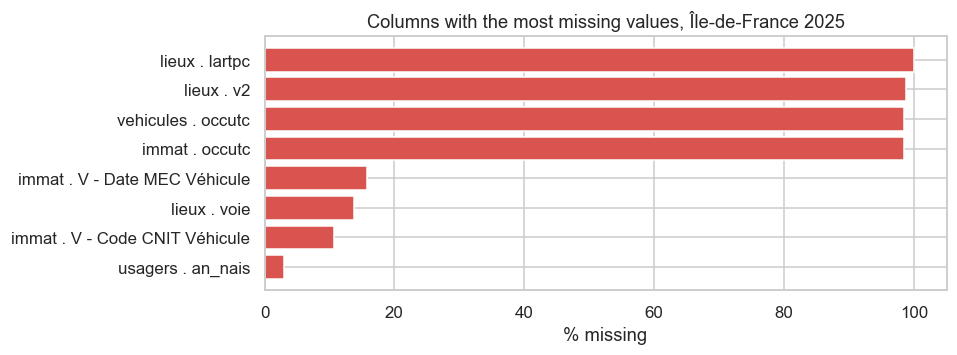

In [4]:
miss = []
for key in idf[LATEST].table_keys:
    df = idf[LATEST].table(key)
    share = df.isna().mean() * 100
    for col, pct in share.items():
        if pct >= 1:
            miss.append({"table": key, "column": col, "missing_%": round(pct, 1)})

miss = pd.DataFrame(miss).sort_values("missing_%", ascending=False)
display(miss.head(20))

fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(miss.head(20)))))
top = miss.head(20).iloc[::-1]
ax.barh(top["table"] + " . " + top["column"], top["missing_%"], color="#d9534f")
ax.set_xlabel("% missing")
ax.set_title(f"Columns with the most missing values, Île-de-France {LATEST}")
save(fig, "missing_values")
plt.show()

## 3. Accidents per year
Number of accidents in France and in Île-de-France, and the IDF share of the national total.

,france,idf,idf_share_%
year,,,
2022,55302,16358,29.6
2023,54822,21958,40.1
2024,54402,35332,64.9
2025,55093,26354,47.8


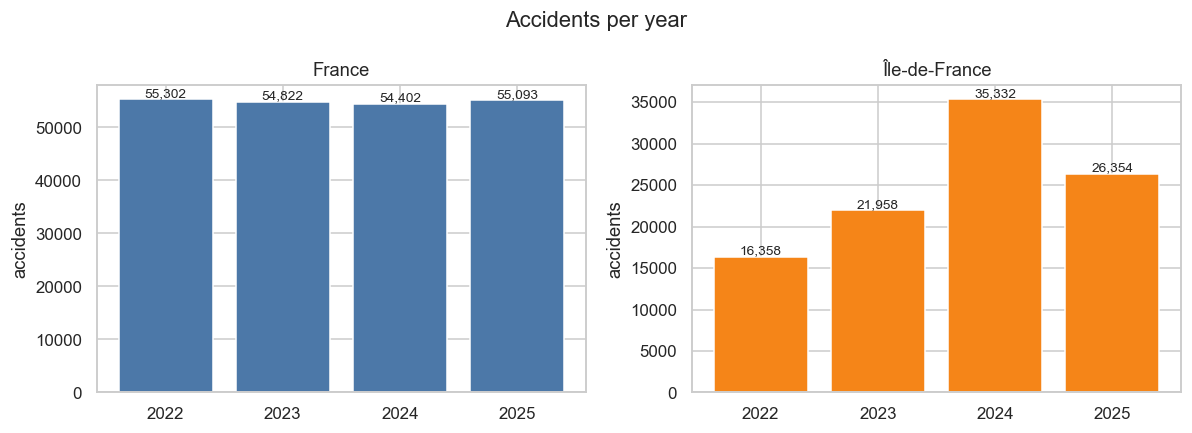

In [5]:
per_year = pd.DataFrame({
    "france": {y: len(find_table(national[y], "Num_Acc", "com")) for y in YEARS},
    "idf":    {y: len(find_table(idf[y], "Num_Acc", "com")) for y in YEARS},
})
per_year["idf_share_%"] = (per_year["idf"] / per_year["france"] * 100).round(1)
per_year.index.name = "year"
display(per_year)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, color in zip(axes, ["france", "idf"], ["#4c78a8", "#f58518"]):
    ax.bar(per_year.index.astype(str), per_year[col], color=color)
    ax.set_title("France" if col == "france" else "Île-de-France")
    ax.set_ylabel("accidents")
    for i, v in enumerate(per_year[col]):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
fig.suptitle("Accidents per year")
fig.tight_layout()
save(fig, "accidents_per_year")
plt.show()

## 4. When do accidents happen?
Île-de-France, all years pooled. Month, day of the week and hour of the day.

In [6]:
def prepare_caract(ds):
    c = find_table(ds, "Num_Acc", "jour", "mois", "hrmn").copy()
    year = pd.to_numeric(c["an"], errors="coerce")
    year = year.where(year > 100, year + 2000)          # some years use 2 digits
    c["date"] = pd.to_datetime(dict(year=year, month=c["mois"], day=c["jour"]), errors="coerce")
    c["hour"] = pd.to_numeric(c["hrmn"].astype(str).str.extract(r"^(\d{1,2})")[0], errors="coerce")
    c["weekday"] = c["date"].dt.dayofweek
    c["year"] = c["date"].dt.year
    return c

caract = pd.concat([prepare_caract(idf[y]) for y in YEARS], ignore_index=True)
print(f"{len(caract):,} accidents, {caract['date'].isna().sum()} with an invalid date")

62,427 accidents, 0 with an invalid date


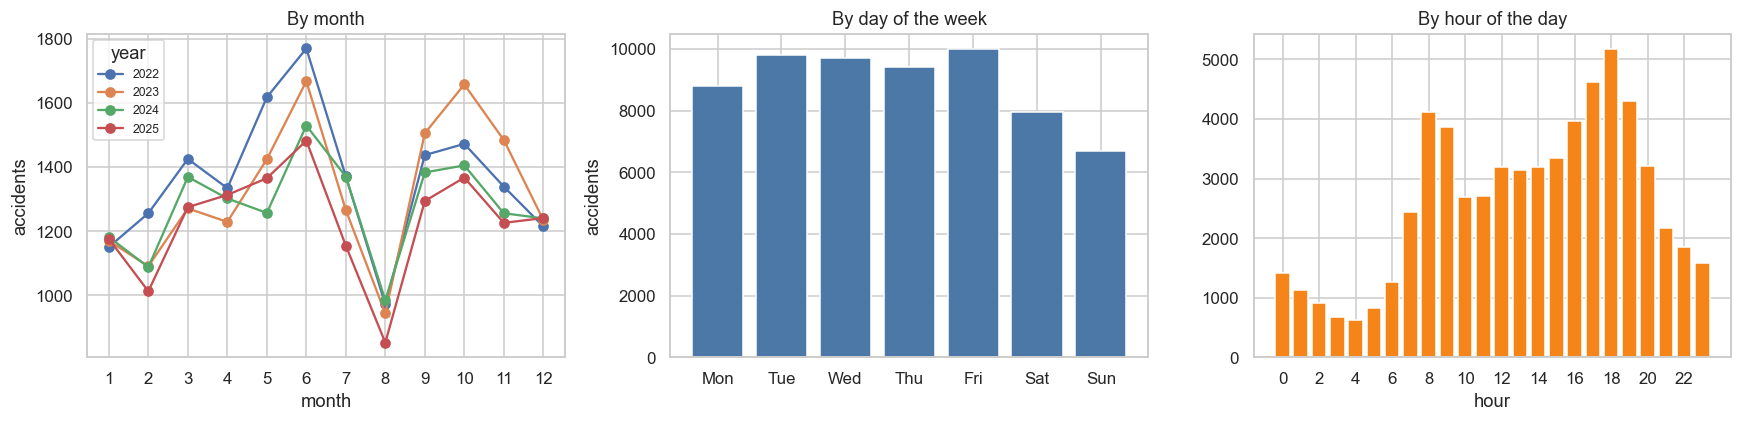

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

monthly = caract.groupby([caract["date"].dt.month, "year"]).size().unstack()
monthly.plot(ax=axes[0], marker="o")
axes[0].set(title="By month", xlabel="month", ylabel="accidents", xticks=range(1, 13))
axes[0].legend(title="year", fontsize=8)

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd = caract["weekday"].value_counts().sort_index()
axes[1].bar(days, wd.values, color="#4c78a8")
axes[1].set(title="By day of the week", ylabel="accidents")

hr = caract["hour"].value_counts().sort_index()
axes[2].bar(hr.index, hr.values, color="#f58518")
axes[2].set(title="By hour of the day", xlabel="hour", xticks=range(0, 24, 2))

fig.tight_layout()
save(fig, "when_accidents_happen")
plt.show()

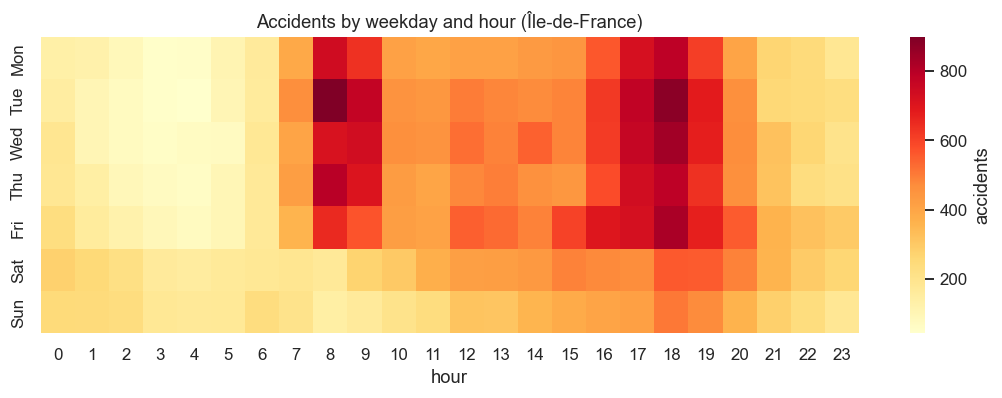

In [8]:
# Hour x weekday heatmap: shows commuting peaks on weekdays vs the weekend night pattern
heat = caract.pivot_table(index="weekday", columns="hour", values="Num_Acc", aggfunc="count")
heat.index = days
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, cbar_kws={"label": "accidents"})
ax.set(title="Accidents by weekday and hour (Île-de-France)", xlabel="hour", ylabel="")
save(fig, "heatmap_weekday_hour")
plt.show()

## 5. How severe are they?
`grav` is recorded per **user**: 1 = unscathed, 2 = killed, 3 = hospitalised, 4 = slightly injured.

grav_label,Unscathed,Killed,Hospitalised,Slightly injured
year,,,,
2022,17401,281,1906,17757
2023,16844,268,1911,17334
2024,16301,263,1991,16777
2025,15874,263,1876,16144


grav_label,Unscathed %,Killed %,Hospitalised %,Slightly injured %
year,,,,
2022,46.60,0.75,5.10,47.55
2023,46.33,0.74,5.26,47.68
2024,46.14,0.74,5.64,47.48
2025,46.47,0.77,5.49,47.26


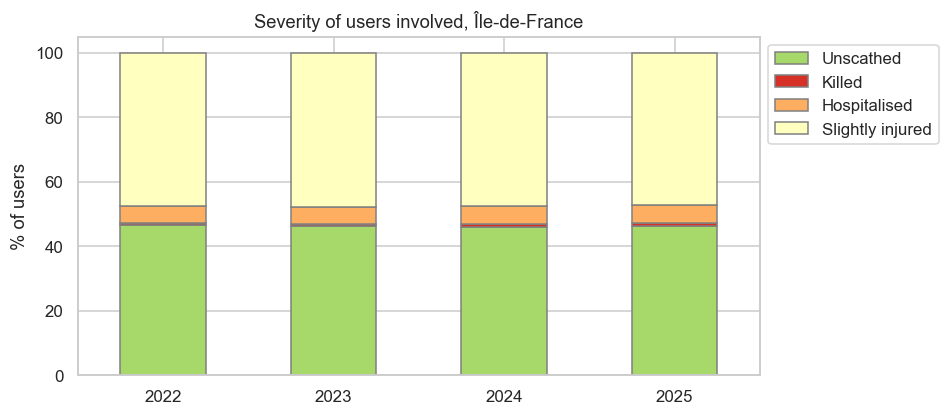

In [9]:
GRAV = {1: "Unscathed", 2: "Killed", 3: "Hospitalised", 4: "Slightly injured"}

def usagers_year(y):
    u = find_table(idf[y], "Num_Acc", "grav", "catu").copy()
    u["year"] = y
    return u

usagers = pd.concat([usagers_year(y) for y in YEARS], ignore_index=True)
usagers["grav_label"] = pd.to_numeric(usagers["grav"], errors="coerce").map(GRAV)

sev = pd.crosstab(usagers["year"], usagers["grav_label"])[list(GRAV.values())]
display(sev)
display((sev.div(sev.sum(axis=1), axis=0) * 100).round(2).add_suffix(" %"))

fig, ax = plt.subplots(figsize=(8, 4))
(sev.div(sev.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=ax,
    color=["#a6d96a", "#d73027", "#fdae61", "#ffffbf"], edgecolor="grey")
ax.set(title="Severity of users involved, Île-de-France", ylabel="% of users", xlabel="")
ax.legend(bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
save(fig, "severity_by_year")
plt.show()

In [10]:
# Accident-level view: worst outcome per accident
worst = (usagers.assign(g=pd.to_numeric(usagers["grav"], errors="coerce"))
         .query("g in [1, 2, 3, 4]")
         .assign(rank=lambda d: d["g"].map({2: 4, 3: 3, 4: 2, 1: 1}))
         .groupby(["year", "Num_Acc"])["rank"].max()
         .map({4: "Fatal", 3: "Hospitalised", 2: "Slight", 1: "No injury"}))
worst_share = (worst.groupby("year").value_counts(normalize=True).unstack()[
    ["Fatal", "Hospitalised", "Slight", "No injury"]] * 100).round(2)
print("Worst outcome per accident (% of accidents)")
display(worst_share)

KeyError: "['No injury'] not in index"

## 6. Conditions
Share of accidents with a fatal or hospitalised user, by light, weather and road surface
(latest year, Île-de-France). A high share means a more severe condition, not necessarily a more frequent one.

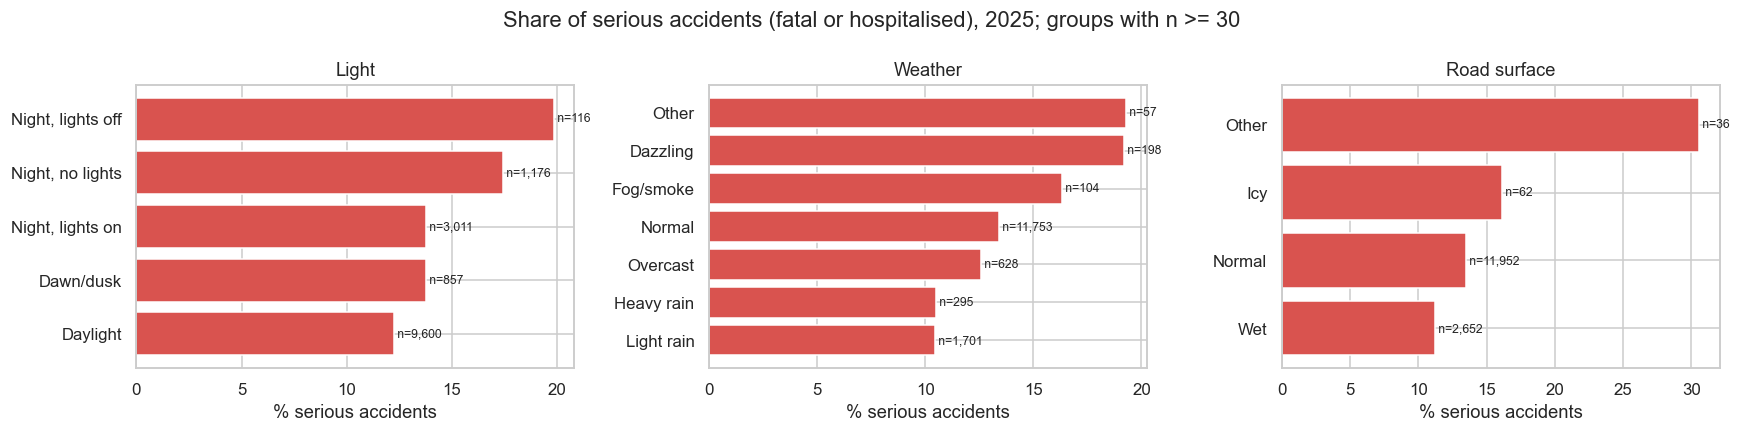

In [11]:
LUM  = {1: "Daylight", 2: "Dawn/dusk", 3: "Night, no lights", 4: "Night, lights off", 5: "Night, lights on"}
ATM  = {1: "Normal", 2: "Light rain", 3: "Heavy rain", 4: "Snow/hail", 5: "Fog/smoke",
        6: "Strong wind", 7: "Dazzling", 8: "Overcast", 9: "Other"}
SURF = {1: "Normal", 2: "Wet", 3: "Puddles", 4: "Flooded", 5: "Snow", 6: "Mud", 7: "Icy", 8: "Oil", 9: "Other"}

c = prepare_caract(idf[LATEST])
l = find_table(idf[LATEST], "Num_Acc", "surf")
acc = (c.merge(l[["Num_Acc", "surf"]].drop_duplicates("Num_Acc"), on="Num_Acc", how="left")
         .merge(worst.loc[LATEST].rename("worst").reset_index(), on="Num_Acc", how="left"))
acc["serious"] = acc["worst"].isin(["Fatal", "Hospitalised"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, mapping, title in zip(axes, ["lum", "atm", "surf"], [LUM, ATM, SURF],
                                   ["Light", "Weather", "Road surface"]):
    t = (acc.assign(label=pd.to_numeric(acc[col], errors="coerce").map(mapping))
            .groupby("label")["serious"].agg(["mean", "size"]))
    t = t[t["size"] >= 30].sort_values("mean")
    ax.barh(t.index, t["mean"] * 100, color="#d9534f")
    ax.set(title=title, xlabel="% serious accidents")
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(m * 100, i, f" n={n:,}", va="center", fontsize=8)
fig.suptitle(f"Share of serious accidents (fatal or hospitalised), {LATEST}; groups with n >= 30")
fig.tight_layout()
save(fig, "conditions_severity")
plt.show()

## 7. Who is involved?
User type, sex, age and vehicle category (Île-de-France, all years).

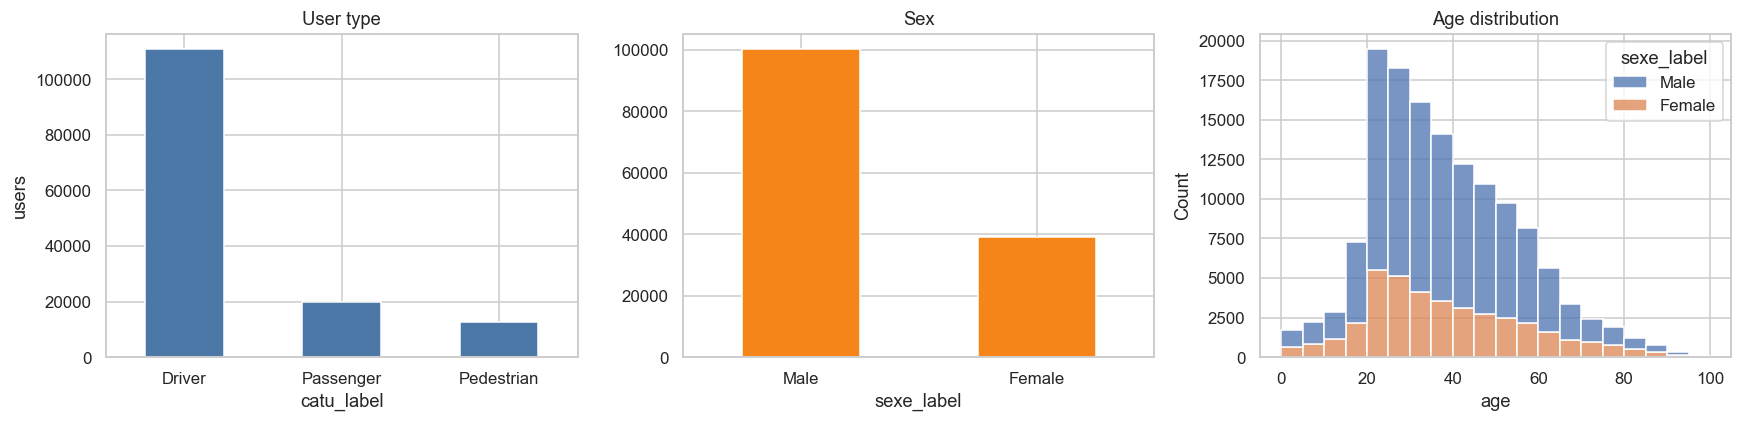

Age missing for 3.2% of users


In [12]:
CATU = {1: "Driver", 2: "Passenger", 3: "Pedestrian"}
SEXE = {1: "Male", 2: "Female"}

u = usagers.copy()
u["catu_label"] = pd.to_numeric(u["catu"], errors="coerce").map(CATU)
u["sexe_label"] = pd.to_numeric(u["sexe"], errors="coerce").map(SEXE)
u["age"] = u["year"] - pd.to_numeric(u["an_nais"], errors="coerce")
u.loc[(u["age"] < 0) | (u["age"] > 100), "age"] = np.nan

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
u["catu_label"].value_counts().plot(kind="bar", ax=axes[0], color="#4c78a8", rot=0)
axes[0].set(title="User type", ylabel="users")

u["sexe_label"].value_counts().plot(kind="bar", ax=axes[1], color="#f58518", rot=0)
axes[1].set(title="Sex")

sns.histplot(data=u.dropna(subset=["age", "sexe_label"]), x="age", hue="sexe_label",
             bins=range(0, 101, 5), multiple="stack", ax=axes[2])
axes[2].set(title="Age distribution", xlabel="age")
fig.tight_layout()
save(fig, "users_profile")
plt.show()

print(f"Age missing for {u['age'].isna().mean():.1%} of users")

In [13]:
# Share of killed or hospitalised, by user type and sex
u["serious"] = pd.to_numeric(u["grav"], errors="coerce").isin([2, 3])
display((u.groupby("catu_label")["serious"].agg(["mean", "size"])
           .assign(mean=lambda d: (d["mean"] * 100).round(1))
           .rename(columns={"mean": "serious_%", "size": "users"})))

,serious_%,users
catu_label,,
Driver,5.2,110832
Passenger,5.3,19706
Pedestrian,15.3,12778


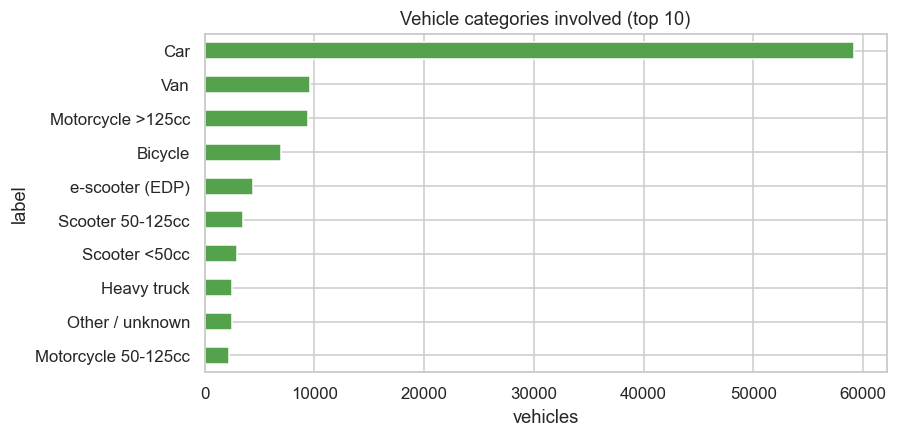

In [14]:
CATV = {1: "Bicycle", 2: "Moped <50cc", 7: "Car", 10: "Van", 13: "Heavy truck", 14: "Heavy truck",
        15: "Heavy truck", 17: "Tractor", 30: "Scooter <50cc", 31: "Motorcycle 50-125cc",
        32: "Scooter 50-125cc", 33: "Motorcycle >125cc", 34: "Scooter >125cc", 37: "Bus",
        38: "Coach", 39: "Train/tram", 40: "Tram", 50: "e-scooter (EDP)", 60: "e-scooter (EDP)",
        80: "e-bike", 99: "Other"}

v = pd.concat([find_table(idf[y], "Num_Acc", "catv") for y in YEARS], ignore_index=True)
v["label"] = pd.to_numeric(v["catv"], errors="coerce").map(CATV).fillna("Other / unknown")
top_v = v["label"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(8, 4))
top_v.iloc[::-1].plot(kind="barh", ax=ax, color="#54a24b")
ax.set(title="Vehicle categories involved (top 10)", xlabel="vehicles")
save(fig, "vehicle_categories")
plt.show()

## 8. Accidents per commune
Île-de-France, latest year, using the same aggregation as the main analysis.
Most communes have few accidents and a handful have very many, so the distribution is strongly skewed.

1,286 communes, 543 with 0 accidents


,accidents per commune
count,1286.0
mean,11.5
std,33.1
min,0.0
25%,0.0
50%,1.0
75%,6.0
max,424.0


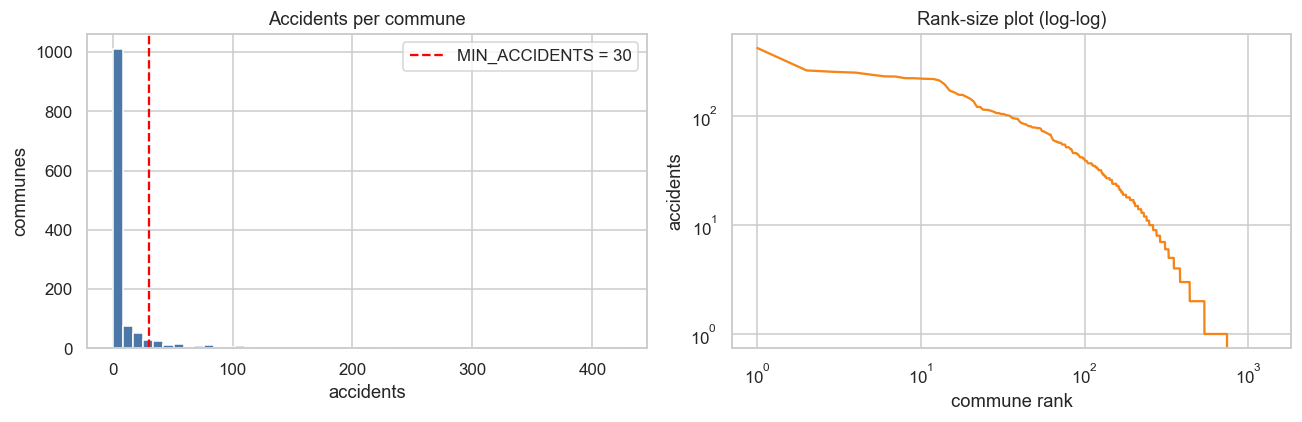

In [15]:
ref = fetch_idf_communes()
by = CommuneAggregator(idf[LATEST], reference_communes=ref).by_commune()

print(f"{len(by):,} communes, {int((by['accidents'] == 0).sum())} with 0 accidents")
display(by["accidents"].describe().round(1).to_frame("accidents per commune"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(by["accidents"], bins=50, color="#4c78a8")
axes[0].set(title="Accidents per commune", xlabel="accidents", ylabel="communes")
axes[0].axvline(30, color="red", ls="--", label="MIN_ACCIDENTS = 30")
axes[0].legend()

sorted_acc = by["accidents"].sort_values(ascending=False).reset_index(drop=True)
axes[1].plot(sorted_acc.index + 1, sorted_acc.values, color="#f58518")
axes[1].set(title="Rank-size plot (log-log)", xlabel="commune rank", ylabel="accidents",
            xscale="log", yscale="log")
fig.tight_layout()
save(fig, "accidents_per_commune")
plt.show()

In [16]:
cum = sorted_acc.cumsum() / sorted_acc.sum() * 100
for pct in (10, 20, 50):
    k = int(len(by) * pct / 100)
    print(f"Top {pct}% of communes ({k}) account for {cum.iloc[k - 1]:.1f}% of accidents")
print(f"Communes at or above 30 accidents (rankable): {int((by['accidents'] >= 30).sum())}")

display(by.sort_values("accidents", ascending=False).head(10))

Top 10% of communes (128) account for 75.3% of accidents
Top 20% of communes (257) account for 90.9% of accidents
Top 50% of communes (643) account for 99.3% of accidents
Communes at or above 30 accidents (rankable): 129


,dep,accidents,vehicles,users,killed,hospitalised,light_injury,unharmed,pedestrians,cyclists,edv_users,vulnerable_accidents,in_reference,severe_per_100_accidents,pct_vulnerable_accidents
com,,,,,,,,,,,,,,,
75116,75,424,783,958,8,41,444,465,74,90,20,158,False,11.6,37.3
75119,75,264,468,581,2,24,277,278,59,62,37,131,False,9.8,49.6
93066,93,256,488,595,1,30,272,292,39,18,23,74,True,12.1,28.9
75112,75,252,477,596,5,19,279,293,43,56,21,95,False,9.5,37.7
75117,75,241,408,524,1,19,261,243,57,43,25,109,False,8.3,45.2
75118,75,233,412,536,3,18,249,266,68,45,26,119,False,9.0,51.1
75113,75,232,416,518,0,18,247,253,50,49,20,108,False,7.8,46.6
92036,92,224,438,553,1,18,257,277,27,16,16,54,True,8.5,24.1
75115,75,224,375,492,3,17,245,227,61,75,17,131,False,8.9,58.5


Top % of communes,Number of communes,Share of accidents (%)
1%,12,20.4
5%,64,56.5
10%,128,75.3
20%,257,90.9
50%,643,99.3
Communes with >= 30 accidents,129,75.5


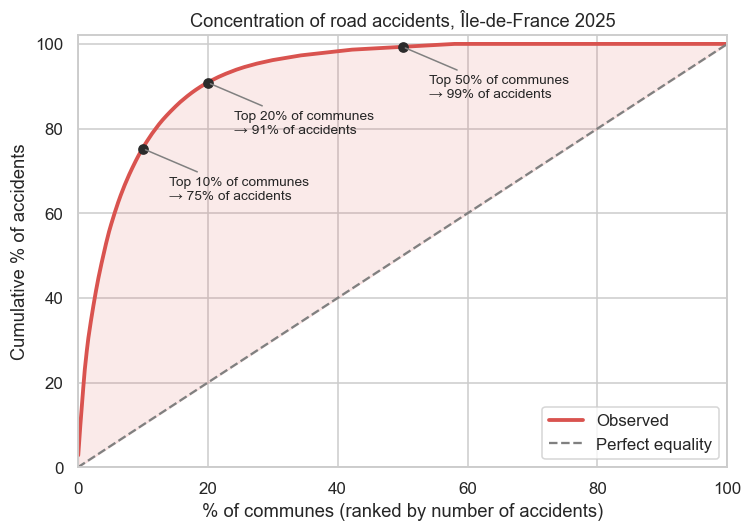

In [17]:
# Concentration of accidents across communes (uses `by` from section 8)
acc_sorted = by["accidents"].sort_values(ascending=False).reset_index(drop=True)
n = len(acc_sorted)
cum_share = acc_sorted.cumsum() / acc_sorted.sum() * 100
x = np.arange(1, n + 1) / n * 100                      # % of communes (most affected first)

# Summary table
levels = [1, 5, 10, 20, 50]
table = pd.DataFrame({
    "Top % of communes": [f"{p}%" for p in levels],
    "Number of communes": [int(n * p / 100) for p in levels],
    "Share of accidents (%)": [round(cum_share.iloc[int(n * p / 100) - 1], 1) for p in levels],
})
table.loc[len(table)] = [f"Communes with >= 30 accidents", int((by["accidents"] >= 30).sum()),
                         round(by.loc[by["accidents"] >= 30, "accidents"].sum()
                               / by["accidents"].sum() * 100, 1)]
display(table.style.hide(axis="index").format({"Share of accidents (%)": "{:.1f}"})
             .set_caption(f"Concentration of accidents across communes, Île-de-France {LATEST}"))

# Figure
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, cum_share, color="#d9534f", lw=2.5, label="Observed")
ax.plot([0, 100], [0, 100], color="grey", ls="--", label="Perfect equality")
ax.fill_between(x, x, cum_share, color="#d9534f", alpha=0.12)

for p in (10, 20, 50):
    y = cum_share.iloc[int(n * p / 100) - 1]
    ax.scatter(p, y, color="#2b2b2b", zorder=3)
    ax.annotate(f"Top {p}% of communes\n→ {y:.0f}% of accidents", (p, y),
                xytext=(p + 4, y - 12), fontsize=9,
                arrowprops=dict(arrowstyle="-", color="grey"))

ax.set(xlim=(0, 100), ylim=(0, 102), xlabel="% of communes (ranked by number of accidents)",
       ylabel="Cumulative % of accidents",
       title=f"Concentration of road accidents, Île-de-France {LATEST}")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "accident_concentration")
plt.show()

## Notes for the report
- State the sources (data.gouv.fr BAAC files) and the years covered.
- Quote the missing-value shares from section 2 as data-quality limits.
- Sections 4, 5 and 6 give the descriptive findings; section 8 motivates the `MIN_ACCIDENTS` threshold.